# Exercise 5 — Exozodi tolerance

*Covers notebooks 05. Difficulty: ★★★☆☆*

Warm dust in the target system adds background right where the planet is. How much can Lazuli tolerate before detection time doubles?

In [1]:
import warnings
import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt
import esc_etc
from esc_etc import Simulation, use_lazuli_style

use_lazuli_style()
warnings.filterwarnings("ignore", module="synphot")

def frame_for(sim, max_frame=1000 * u.s):
    """Frame time to use: max_frame, or half the saturation time if that is shorter."""
    return min(u.Quantity(max_frame, u.s), 0.5 * sim.saturation_time())


def hours_to_snr(sim, snr=5, max_frame=1000 * u.s):
    """Integration time (hours) to reach snr with the current configuration; NaN above the speckle plateau."""
    return sim.get_int_time_for_snr(snr, frame_for(sim, max_frame))["int_time_continuous"][0].to_value(u.hr)

### 5.1 — The sweep

For a Sun twin at 10 pc with a planet at 0.4" (4 AU), R3, raw contrast $10^{-8}$, ppgain 30: sweep
the exozodi level from 0.1 to $10^4$ zodis (1 zodi = 22 V mag/arcsec² at 1 AU, $r^{-2}$) for
planet contrasts $3\times10^{-9}$, $10^{-8}$ and $3\times10^{-8}$. Plot the time to S/N 5 relative
to the no-exozodi time, and find where each curve doubles.

planet 3e-09: no exozodi 3.84 h; doubles at 714 zodi


planet 1e-08: no exozodi 0.31 h; doubles at 888 zodi


planet 3e-08: no exozodi 0.05 h; doubles at 1384 zodi


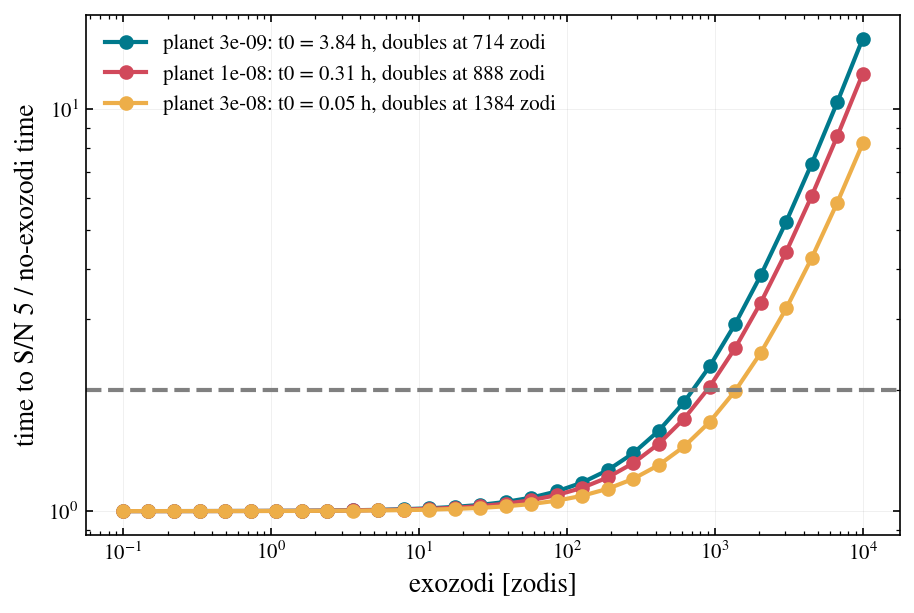

In [2]:
from scipy.optimize import brentq
sim = Simulation.from_default(filter="R3", hoststarmag=4.83, hoststar_band="johnson_v", planetdeltamag=20, contrast=1e-8, ppgain=30, separation=0.4)
r_AU = 0.4 * 10.0
sb = lambda n: 22.0 - 2.5 * np.log10(n) + 5 * np.log10(r_AU)

def hours_at(n_zodi, contrast, raw=1e-8, ppgain=30):
    sim.update(scene__exozodi__mag=99.0 if n_zodi == 0 else sb(n_zodi), scene__exozodi__band="johnson_v",
               scene__planet__deltamag=-2.5 * np.log10(contrast), coronagraph__raw_dh_contrast=raw, coronagraph__ppgain=ppgain)
    h = hours_to_snr(sim); sim.reset(); return h

zodis = np.geomspace(0.1, 1e4, 30)
fig, ax = plt.subplots(figsize=(7, 4.5))
n2 = {}
for c in (3e-9, 1e-8, 3e-8):
    t0 = hours_at(0, c)
    ratio = np.array([hours_at(n, c) for n in zodis]) / t0
    n2[c] = 10 ** brentq(lambda lg: hours_at(10 ** lg, c) / t0 - 2, -1, 5)
    ax.loglog(zodis, ratio, "o-", label=f"planet {c:.0e}: t0 = {t0:.2f} h, doubles at {n2[c]:.0f} zodi")
    print(f"planet {c:.0e}: no exozodi {t0:.2f} h; doubles at {n2[c]:.0f} zodi")
ax.axhline(2, color="0.5", ls="--"); ax.set(xlabel="exozodi [zodis]", ylabel="time to S/N 5 / no-exozodi time"); ax.legend()
plt.show()

> ✏️ **Before you run the next cell:** does the post-processing gain change the zodi level at which the time doubles? Yes, no, or only for faint planets? Write your guess down (or put it in the room poll), then run.

### 5.2 — Post-processing gain

Repeat the $10^{-8}$ curve with ppgain 10 and 100. Does the ratio change? Explain from the
integration-time formula (notebook 04 or `esc_etc/noise.py`).

In [3]:
c = 1e-8
ref = np.array([hours_at(n, c, ppgain=30) for n in zodis]) / hours_at(0, c, ppgain=30)
for g in (10, 100):
    ratio = np.array([hours_at(n, c, ppgain=g) for n in zodis]) / hours_at(0, c, ppgain=g)
    print(f"ppgain {g:3d}: t0 = {hours_at(0, c, ppgain=g):.2f} h, max |ratio - ratio(ppgain 30)| = {np.max(np.abs(ratio - ref)):.1e}")
# t = (S + B) / [(S/SNR)^2 - M^2]: exozodi only adds to B in the numerator, ppgain only changes M in the denominator, so the ratio is independent of ppgain.

ppgain  10: t0 = 0.40 h, max |ratio - ratio(ppgain 30)| = 4.4e-16


ppgain 100: t0 = 0.30 h, max |ratio - ratio(ppgain 30)| = 1.8e-15


### 5.3 — The habitable zone of a nearby star

Repeat 5.1 for tau Ceti (V = 3.5, 3.65 pc) with a planet at 0.7 AU (0.19"), contrast
$10^{-9}$ (a large, bright super-Earth), ppgain 100. Where does the time double now, and why is the
number so different?

In [4]:
sim = Simulation.from_default(filter="R3", hoststarmag=3.5, hoststar_band="johnson_v", planetdeltamag=22.5, contrast=1e-8, ppgain=100, separation=0.7 / 3.65)
r_AU = 0.7
t0 = hours_at(0, 1e-9, ppgain=100)
ratio = np.array([hours_at(n, 1e-9, ppgain=100) for n in zodis]) / t0
print(f"tau Ceti HZ: no exozodi {t0:.1f} h; 1 zodi = {sb(1):.2f} V mag/arcsec²; doubles at {np.interp(2, ratio, zodis):.0f} zodi")
# At 0.7 AU each zodi is (4/0.7)^2 = 33 times brighter than at 4 AU, and the planet is far fainter, so the dust competes much sooner.

tau Ceti HZ: no exozodi 8.3 h; 1 zodi = 21.23 V mag/arcsec²; doubles at 46 zodi


> 🤖 **Ask Jupyter AI:** *Add a systematic exozodi residual to the noise model: a fraction f of the exozodi rate that does not average down, entering like the speckle floor M. For f = 0.01 and 0.1, how does the tolerance in 5.3 change?*
>
> Ask it to subclass AnalyticCoronagraphNoiseModel rather than patch the package.

***
## Share-back and feedback

Bring back **one plot and one number** to the share-back board, and the observing decision you draw
from them.

> 🤖 **Ask Jupyter AI:** *Draft a GitHub issue for schmidt-observatories/esc-etc describing one thing I
> found missing, confusing or wrong in this exercise, with a minimal code example.*